Water Wavelength [mm] =  1.4095238095238096
Material Quater Wavelength [mm] = 0.63 mm


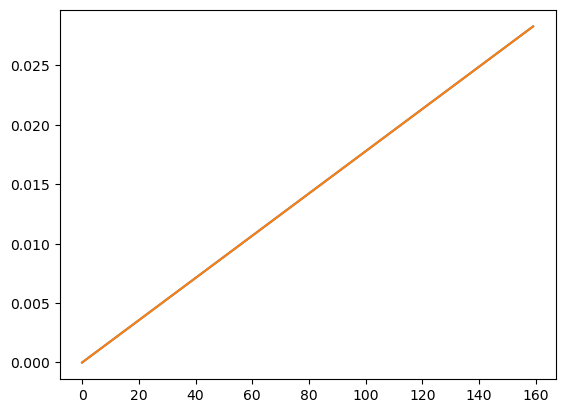

In [1]:
import numpy as np
from math import pi
import pyvista as pv
import matplotlib.pyplot as plt

def cart2pol(x, y):
    rho = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)
    return(rho, phi)

# General Parameters
c_water = 1480
c_resin = 2636 
c_aluminium = 6420

c_material = c_resin


# Define Source Parameters
f = 1.05e6
wavelength = c_water/f
print('Water Wavelength [mm] = ', wavelength * 1e3)
print(f'Material Quater Wavelength [mm] = {c_material/(4*f)*1e3:.2f} mm')


k = 2*pi*f/c_water

diameter = np.sqrt(2)*40e-3

# Computational ("Domain") Parameters
domain_width = diameter
ppw = 2**2 # points per wavelength 2**4 recommended limit

dx = 2*pi/k/ppw # spatial step
Nx = int(diameter/dx) # number of points in radial direction
Ny = Nx # number of points in angular direction

# Radial grid
r = np.linspace(0, domain_width/2, Nx)
plt.plot(r)
# r = (domain_width / 2) * (np.linspace(0, 1, Nx))**(2/3)
plt.plot(r)
theta = np.linspace(0, 2*pi, Ny)
R, Theta = np.meshgrid(r, theta)
X = R * np.cos(Theta)
Y = R * np.sin(Theta)

# Example Source
P0 = np.ones((Ny, Nx))
P0[R > diameter/2] = 0

# Add Focus
focal_z = 34*1e-3
focal_x = 0
focal_y = 0
focal_point = np.round([focal_x, focal_y, focal_z], 3) * 1e3
r = np.sqrt((X - focal_x)**2 + (Y - focal_y)**2 + focal_z**2)
P0 = P0 * np.exp(1j * k * r)

# m=1
# P0*= np.exp(1j*m*Theta)

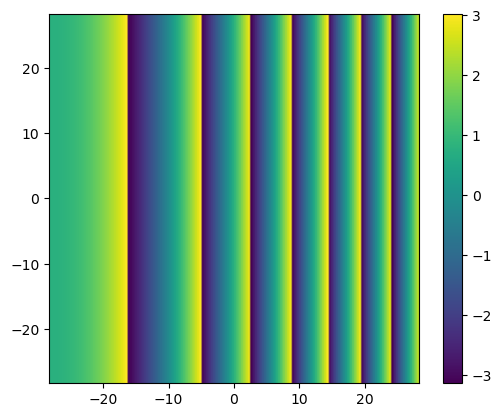

In [2]:
plt.imshow(np.angle(P0), extent=[-domain_width/2*1e3, domain_width/2*1e3, -domain_width/2*1e3, domain_width/2*1e3])
plt.xlabel('')
plt.colorbar()

0.0


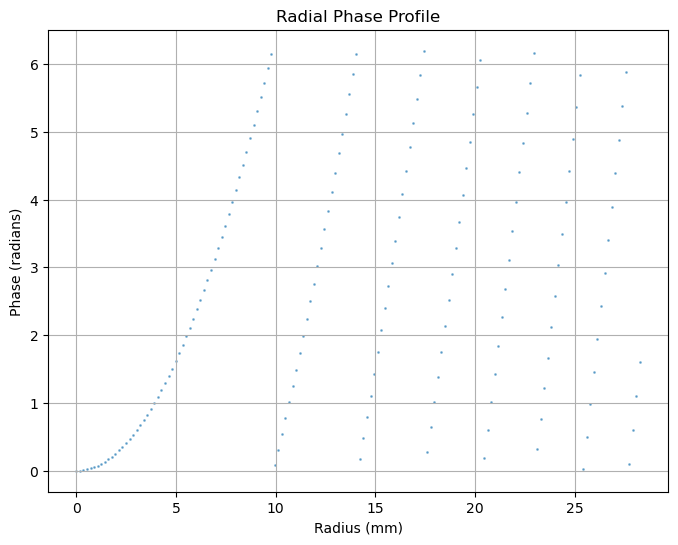

In [3]:

#### Generate Lens Profile ####

def delH(delPhase, c1, c2, f0):
    # ∆φ(x, y) = (k − k )∆T(x, y) Equation 8 kai melde Holograms for acoustics
    k1 = 2 * np.pi * f0 / c1
    k2 = 2 * np.pi * f0 / c2
    return delPhase / (k2 - k1)

# Unwrap the phase to remove discontinuities
P0_phase = np.unwrap(np.angle(P0), axis=1) 
P0_phase -= np.min(P0_phase)
print(np.min(P0_phase))
P0_phase = np.mod(P0_phase,2*pi)

# Plot the radial phase
# Plot the radial phase profile similar to the thickness radial plot
radial_r = R[int(Ny/2), :] * 1e3  # radius in mm
radial_phase = P0_phase[int(Ny/2), :]

plt.figure(figsize=(8, 6))
plt.scatter(radial_r, radial_phase, s=1, alpha=0.5)
plt.title('Radial Phase Profile')
plt.xlabel('Radius (mm)')
plt.ylabel('Phase (radians)')
plt.grid(True)
plt.show()

thickness = delH(P0_phase, c_material, c_water, f)

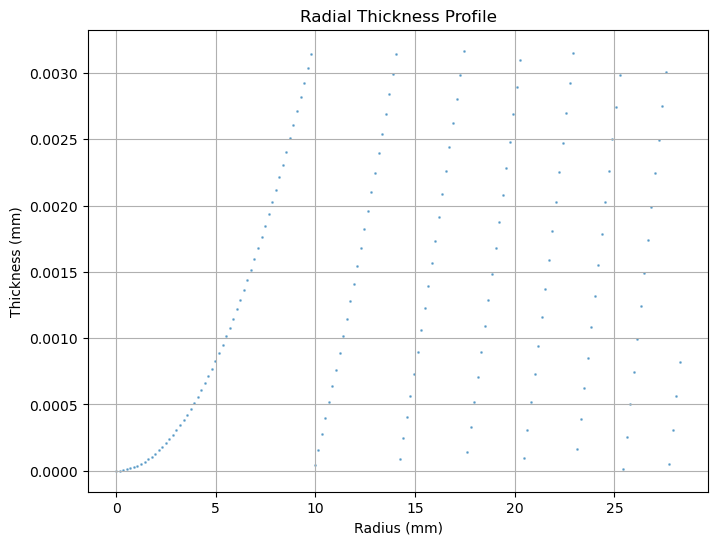

In [4]:
plt.figure(figsize=(8, 6))
plt.scatter(radial_r, thickness[int(Ny/2), :], s=1, alpha=0.5)
plt.title('Radial Thickness Profile')
plt.xlabel('Radius (mm)')
plt.ylabel('Thickness (mm)')
plt.grid(True)
plt.show()


In [5]:
grid = pv.StructuredGrid(X, Y, thickness)
surface = grid.extract_surface()
surface.plot(cmap='viridis', show_edges=True)
surface.save('thickness_profile.stl')

/var/folders/_f/7y9420f51bxgm9tns2f59x_r0000gp/T/ipykernel_44368/3413232321.py:2: PyVistaFutureWarning: The default value of `algorithm` for the filter
`StructuredGrid.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  surface = grid.extract_surface()


Widget(value='<iframe src="http://localhost:65317/index.html?ui=P_0x30f1a5d30_0&reconnect=auto" class="pyvista…

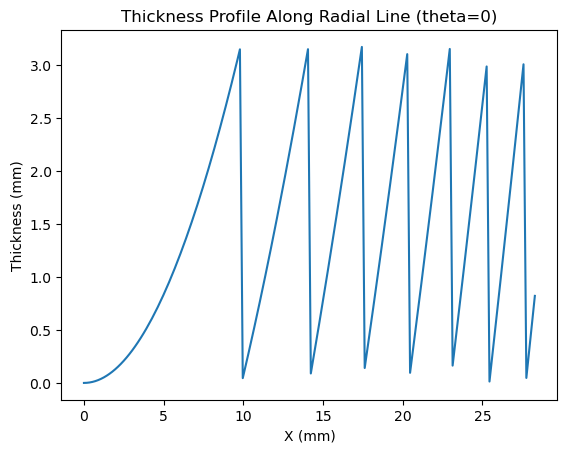

In [6]:
# For axially symmetric lens, we can take a slice along one radial line (e.g., theta = 0) to get the thickness profile as a function of radius.

slice_idx = 0  # choose one radial line (theta = 0)
x_slice = X[slice_idx, :]
y_slice = Y[slice_idx, :]
z_slice = thickness[slice_idx, :]

plt.plot(x_slice*1e3, z_slice*1e3)  # Convert to mm for plotting
plt.xlabel('X (mm)')
plt.ylabel('Thickness (mm)')
plt.title('Thickness Profile Along Radial Line (theta=0)')

data = np.column_stack((x_slice, y_slice, z_slice))*1e2 # Convert to mm
np.savetxt("slice_xyz.csv", data, delimiter=",", header="X,Y,Z", comments="")

In [13]:
wavelength_m = c_resin/f
uniform_thickness = 5*wavelength_m/4
lens_thickness = np.max(thickness) 

print(f'Uniform Thickness = {uniform_thickness*1e3:.2f} mm')
print(f'Maximum Lens Thickness = {lens_thickness*1e3:.2f} mm')
print(f'Total Lens Thickness = {(uniform_thickness+lens_thickness)*1e3:.2f}')
print(f'Mean Thickness = {(uniform_thickness+np.mean(thickness))*1e3:.2f} mm')

Uniform Thickness = 3.14 mm
Maximum Lens Thickness = 3.17 mm
Total Lens Thickness = 6.31
Mean Thickness = 4.50 mm
